In [16]:
import csv
import time

from src.sorting import sort_parcels
from src.knapsack import knapsack
from src.dijkstra import (
    load_graph,
    print_graph,
    print_shortest_paths,
    plot_graph
)
from src.tsp import delivery_route
import matplotlib.pyplot as plt


In [17]:
def load_parcels(filename):
    parcels = []
    with open(filename, "r", newline="") as file:
        reader = csv.DictReader(file)
        for row in reader:
            parcels.append({
                "id": row["parcel_id"],
                "destination": row["destination"],
                "weight": int(row["weight"]),
                "value": int(row["value"]),
                "priority": int(row["priority"]),
                "deadline": row["deadline"]
            })
    return parcels




--- PHASE 3: ROAD GRAPH ---
A -> B (4 km), C (3 km), D (5 km), D0 (5 km)
B -> A (4 km), C (3 km), D0 (7 km), E (5 km), F (9 km)
C -> A (3 km), B (3 km), D (4 km), D0 (4 km), E (6 km), F (7 km)
D -> A (5 km), C (4 km), D0 (6 km), F (4 km)
D0 -> A (5 km), B (7 km), C (4 km), D (6 km), E (12 km), F (8 km)
E -> B (5 km), C (6 km), D0 (12 km), F (8 km)
F -> B (9 km), C (7 km), D (4 km), D0 (8 km), E (8 km)

Road graph image saved to: images/road_graph.png


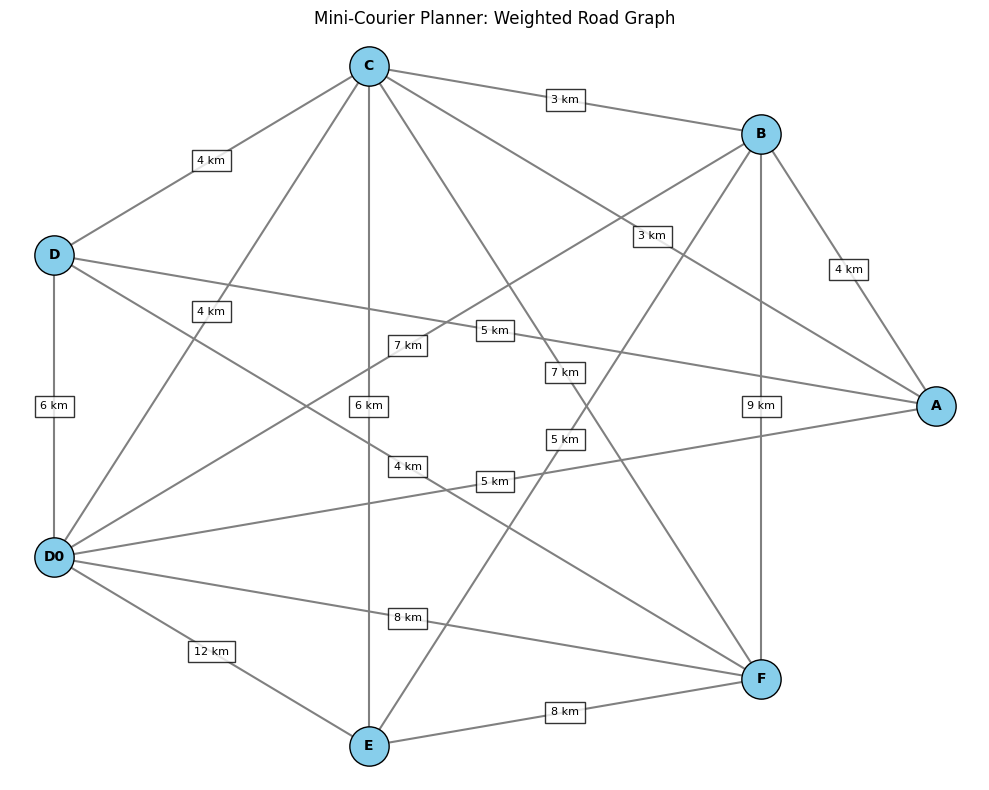


--- PHASE 3: DIJKSTRA SHORTEST PATHS ---

Destination: A
Shortest path: D0 -> A
Shortest distance: 5.0 km

Destination: B
Shortest path: D0 -> B
Shortest distance: 7.0 km

Destination: C
Shortest path: D0 -> C
Shortest distance: 4.0 km


In [18]:

capacity = 15
depot = "D0"

parcels = load_parcels("datasets/parcels.csv")
graph = load_graph("datasets/roads.csv")

print_graph(graph)
plot_graph(graph)

start = time.perf_counter()
prioritized = sort_parcels(parcels)
sorting_time = time.perf_counter() - start

start = time.perf_counter()
selected, total_value,dp = knapsack(prioritized, capacity)
packing_time = time.perf_counter() - start

destinations = sorted({
    parcel["destination"] for parcel in selected
})

print_shortest_paths(graph, depot, destinations)




In [19]:
start = time.perf_counter()

route, distance, visit_order = delivery_route(graph, depot, destinations)

routing_time = time.perf_counter() - start

In [20]:
print("\n===== MINI-COURIER PLANNER =====")
print("Vehicle capacity:", capacity, "kg")
print("Total parcels:", len(parcels))
print("Selected parcels:", len(selected))
print("Packed weight:",
          sum(p["weight"] for p in selected), "kg")
print("Total parcel value:", total_value)

print("\n--- PACKING PLAN ---")
for parcel in selected:
    print(
            parcel["id"],
            "| Destination:", parcel["destination"],
            "| Weight:", parcel["weight"], "kg",
            "| Value:", parcel["value"],
            "| Priority:", parcel["priority"]
    )
    
print("\n--- PHASE 2: SORTED PARCELS ---")
for parcel in prioritized:
    print(
            parcel["id"],
            "| Priority:", parcel["priority"],
            "| Deadline:", parcel["deadline"],
            "| Weight:", parcel["weight"], "kg",
            "| Value:", parcel["value"]
    )

print("\n--- PHASE 2: DP TABLE ---")
print("Capacity:", list(range(capacity + 1)))

for i, row in enumerate(dp):
    print(f"Row {i}: {row}")

print("\n--- PHASE 2: PACKING RESULT ---")
print("Selected parcel IDs:",
          [p["id"] for p in selected])
print("Total packed weight:",
          sum(p["weight"] for p in selected), "kg")
print("Maximum total value:", total_value)



===== MINI-COURIER PLANNER =====
Vehicle capacity: 15 kg
Total parcels: 10
Selected parcels: 5
Packed weight: 15 kg
Total parcel value: 325

--- PACKING PLAN ---
P03 | Destination: C | Weight: 3 kg | Value: 70 | Priority: 5
P01 | Destination: A | Weight: 4 kg | Value: 80 | Priority: 5
P09 | Destination: A | Weight: 2 kg | Value: 45 | Priority: 4
P08 | Destination: C | Weight: 4 kg | Value: 90 | Priority: 3
P05 | Destination: B | Weight: 2 kg | Value: 40 | Priority: 2

--- PHASE 2: SORTED PARCELS ---
P03 | Priority: 5 | Deadline: 2026-10-21 | Weight: 3 kg | Value: 70
P01 | Priority: 5 | Deadline: 2026-10-22 | Weight: 4 kg | Value: 80
P09 | Priority: 4 | Deadline: 2026-10-21 | Weight: 2 kg | Value: 45
P02 | Priority: 4 | Deadline: 2026-10-23 | Weight: 6 kg | Value: 110
P06 | Priority: 4 | Deadline: 2026-10-25 | Weight: 7 kg | Value: 130
P08 | Priority: 3 | Deadline: 2026-10-23 | Weight: 4 kg | Value: 90
P04 | Priority: 3 | Deadline: 2026-10-24 | Weight: 5 kg | Value: 95
P05 | Priority: 

In [21]:
print("\n--- PHASE 3: FINAL DELIVERY ROUTE ---")

print("Delivery stop order:")
print(" -> ".join(visit_order))

print("\nComplete road path:")
print(" -> ".join(route))

print("\nTotal route distance:",
      round(distance, 2), "km")

print(f"Route planning time: {routing_time * 1000:.4f} ms")

print("\n--- EXECUTION TIMES ---")
print(f"Sorting: {sorting_time * 1000:.4f} ms")
print(f"Knapsack DP: {packing_time * 1000:.4f} ms")
print(f"Route planning: {routing_time * 1000:.4f} ms")



--- PHASE 3: FINAL DELIVERY ROUTE ---
Delivery stop order:
D0 -> C -> A -> B -> D0

Complete road path:
D0 -> C -> A -> B -> D0

Total route distance: 18.0 km
Route planning time: 0.2020 ms

--- EXECUTION TIMES ---
Sorting: 0.0898 ms
Knapsack DP: 0.0943 ms
Route planning: 0.2020 ms


In [22]:
from src.analysis import run_tests, run_comparisons

print("=== CORRECTNESS TESTS ===")
run_tests()

=== CORRECTNESS TESTS ===
PASS  merge sort matches Python sorted() on sample data
PASS  knapsack value 325 equals brute-force optimum 325
PASS  Dijkstra distances match Floyd-Warshall for every source node
PASS  nearest-neighbour route D0->C->A->B->D0 = 18 km


In [23]:
print("=== ALGORITHM COMPARISONS ===")
run_comparisons()

=== ALGORITHM COMPARISONS ===

SORTING (ms)      n   merge   bubble  built-in
                100    0.55     3.04     0.10
                500    3.57   100.33     0.30
               1000    5.26   248.41     0.78

KNAPSACK: DP vs greedy (value/weight ratio)
  sample data, capacity 15 : DP = 325, greedy = 310
  200 random sets (15 parcels, cap 25): DP strictly better in 95

TSP: nearest neighbour vs brute force
  3 stops (A,B,C): NN = 18 km, optimal = 16 km (12.5% longer), brute force took 0.05 ms
  6 stops (A-F): NN = 34 km, optimal = 34 km (0.0% longer), brute force took 1.08 ms


    n   sort(ms)   knapsack(ms)   dijkstra(ms)   routing(ms)
   10       0.07           0.13           0.04          0.48
   25       0.14           0.80           0.06          1.47
   50       0.40           3.71           0.14          8.76
  100       0.79          12.34           0.18         21.44


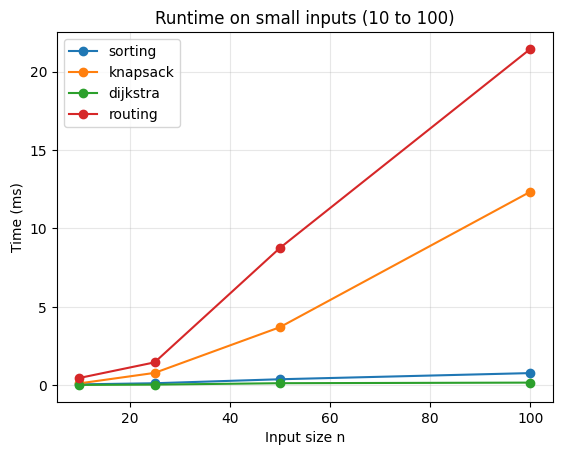

In [24]:
with open("images/runtime_results.csv") as f:
    rows = list(csv.DictReader(f))

print(f"{'n':>5} {'sort(ms)':>10} {'knapsack(ms)':>14} {'dijkstra(ms)':>14} {'routing(ms)':>13}")
for r in rows:
    print(f"{r['input_size']:>5} {float(r['sorting_ms']):>10.2f} "
          f"{float(r['knapsack_ms']):>14.2f} {float(r['dijkstra_ms']):>14.2f} "
          f"{float(r['routing_ms']):>13.2f}")

sizes = [int(r["input_size"]) for r in rows]
for col in ("sorting_ms", "knapsack_ms", "dijkstra_ms", "routing_ms"):
    plt.plot(sizes, [float(r[col]) for r in rows], marker="o", label=col.replace("_ms", ""))
plt.xlabel("Input size n")
plt.ylabel("Time (ms)")
plt.title("Runtime on small inputs (10 to 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

{'n': 100, 'sort_ms': 0.61, 'knapsack_ms': 6.94, 'dijkstra_ms': 0.35, 'routing_ms': 22.84}
{'n': 200, 'sort_ms': 1.1, 'knapsack_ms': 26.85, 'dijkstra_ms': 0.6, 'routing_ms': 77.91}
{'n': 500, 'sort_ms': 2.47, 'knapsack_ms': 199.26, 'dijkstra_ms': 1.44, 'routing_ms': 532.91}
{'n': 1000, 'sort_ms': 5.34, 'knapsack_ms': 652.99, 'dijkstra_ms': 2.86, 'routing_ms': 2499.4}


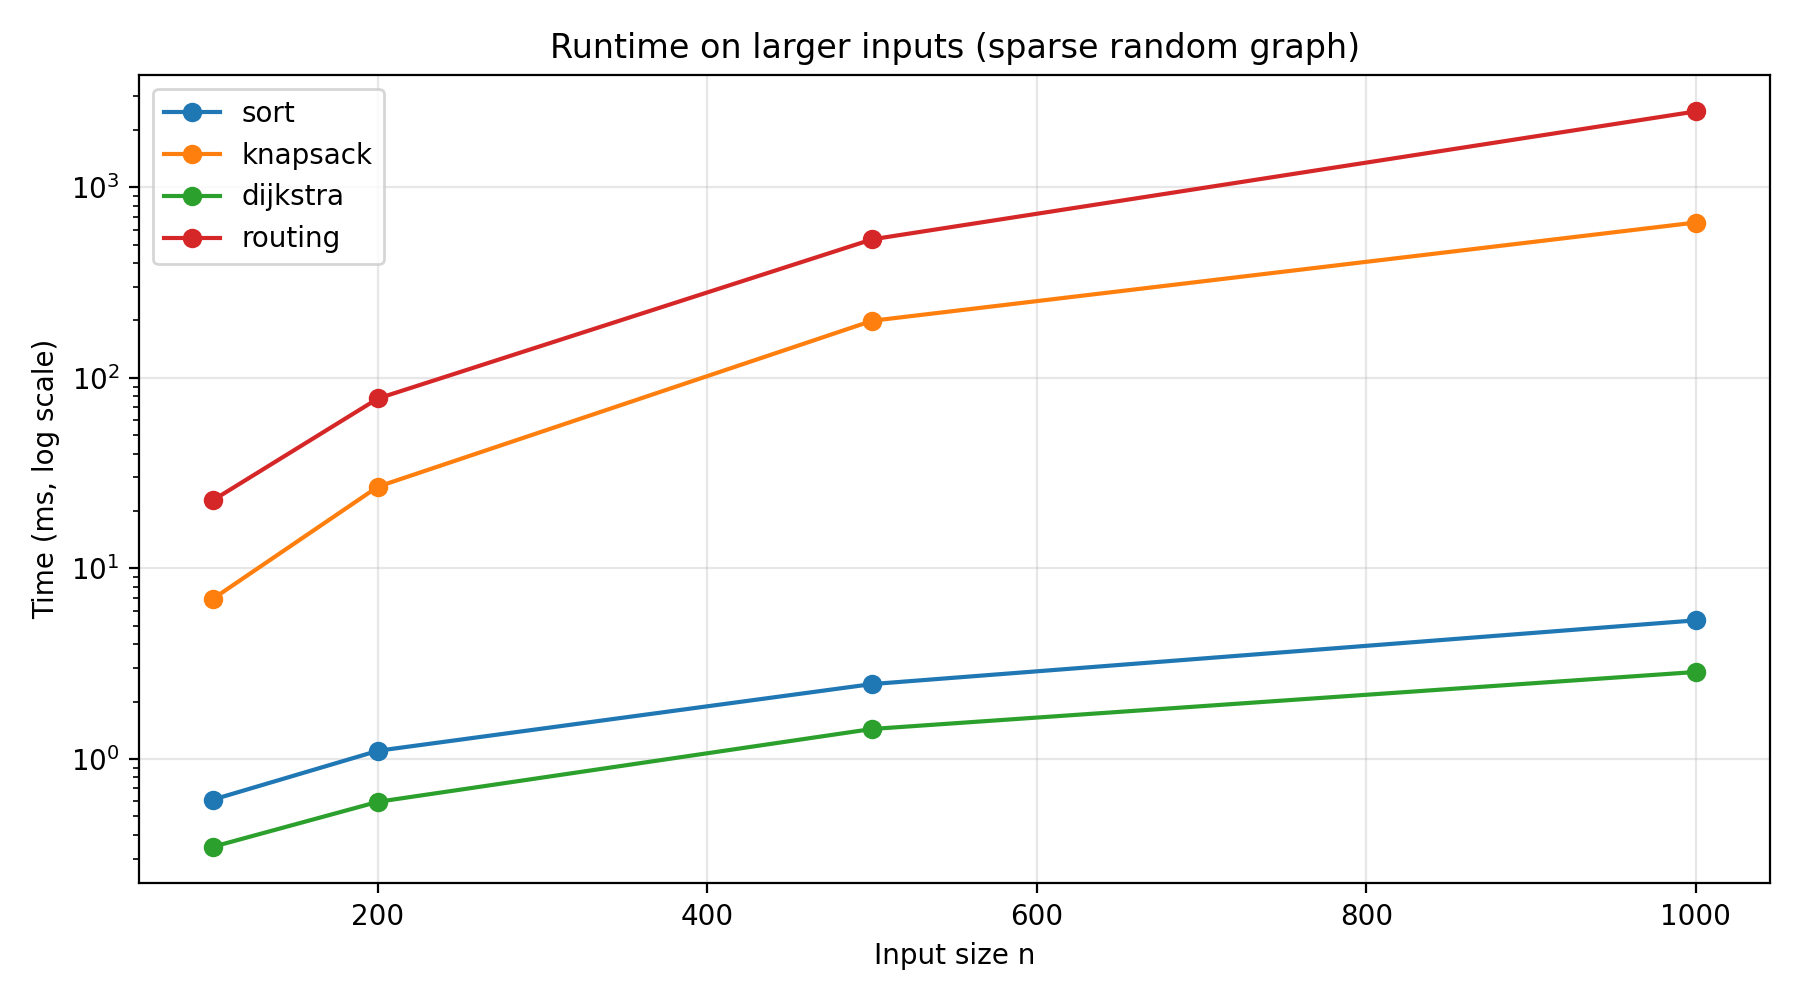

In [25]:
from src.analysis import run_large_benchmark
from IPython.display import Image, display

run_large_benchmark()                      # takes a few seconds
display(Image("images/runtime_large.png", width=700))


route image saved to images/route_map.png


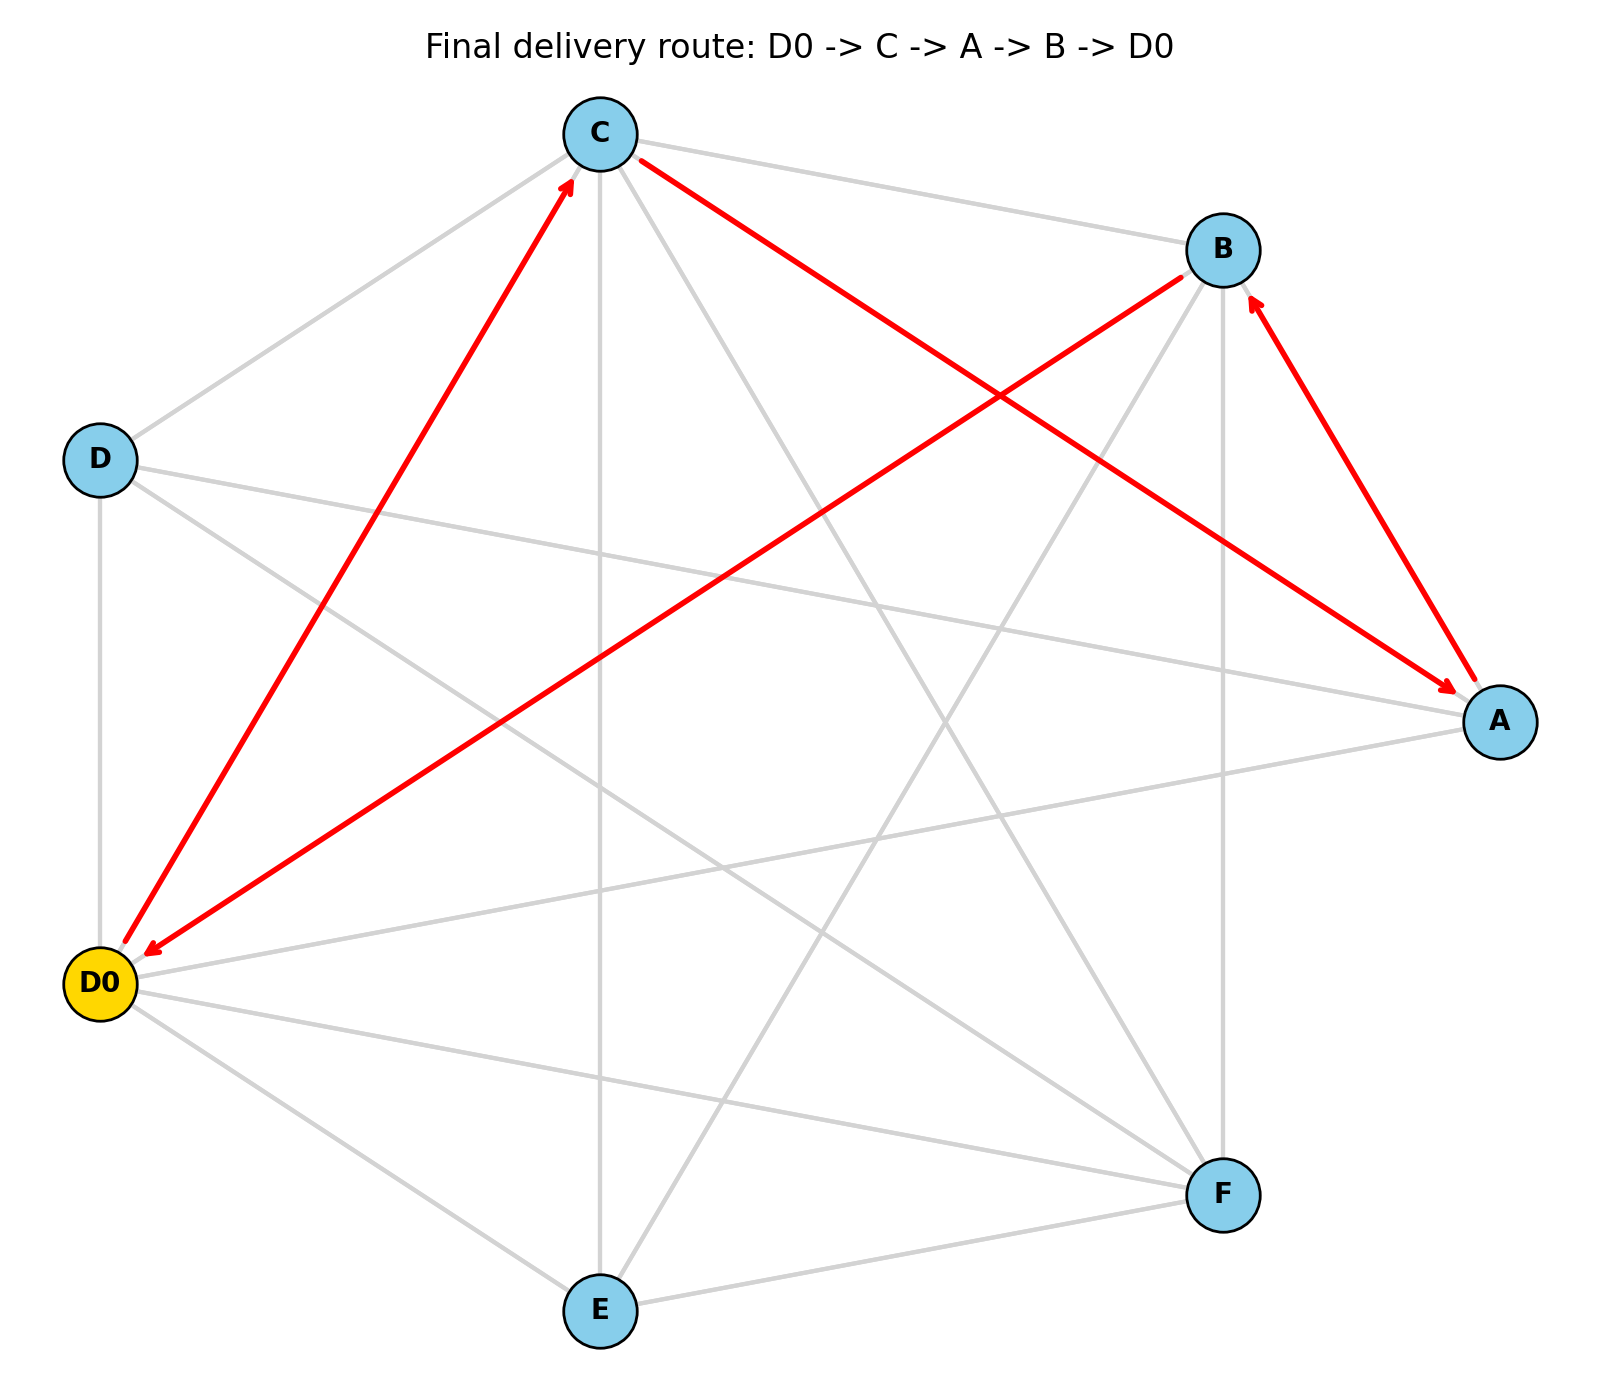

In [26]:
from src.analysis import plot_route
from IPython.display import Image, display

plot_route(graph, route)                   # graph and route come from the earlier cells
display(Image("images/route_map.png", width=500))